In [1]:
library(tidyverse)
library(tximport)
library(DESeq2)
library(rtracklayer)
library(edgeR)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.1     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’

In [2]:
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15), rect=element_rect(linewidth=1)))

In [3]:
#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz"
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation_tss.1kb.bed", header=F, sep='\t')

In [4]:
#generate rowdata

row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

In [5]:
#read in data
dir <- "/mnt/storage/home/agulka/projects/0823_Dual_Treatment/RNA_seq/"
files <- c("dmso_r1/rsem_quant/rep1/rep1_dmso_r1_anno_rsem.genes.results", "dmso_r2/rsem_quant/rep1/rep1_dmso_r2_anno_rsem.genes.results", "brm_r1/rsem_quant/rep1/rep1_brm_r1_anno_rsem.genes.results", "brm_r2/rsem_quant/rep1/rep1_brm_r2_anno_rsem.genes.results")

txi <- tximport(files=paste0(dir,files), txIn=F, type="rsem")

#filter to remove lowly expressed genes
filt <- which(apply(txi$abundance, MARGIN=1, FUN=max) <=1 | apply(txi$length, MARGIN=1, FUN=min)==0)

txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#subset row metadata to only include genes to be assayed
row.data <- row.data[match(gsub("\\..*$", "", rownames(txi$abundance)), row.data$gene_id_base),]

reading in files with read_tsv

1 
2 
3 
4 




In [6]:
#make coldata
col.data <- data.frame("condition"=c("dmso", "dmso", "brm", "brm"), rep=c(1,2,1,2))

In [7]:
#run DESeq2
dds <- DESeqDataSetFromTximport(txi, colData=col.data, design = ~condition)
des <- DESeq(dds)
res <- results(des, contrast=c("condition", "brm", "dmso"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [8]:
#Identify genes that are unchanging with BRM014 treatment
#Criteria: p.adj > 0.2, 0.8 < fold change < 1.2
no_change <- which(res$padj > 0.2 & res$log2FoldChange > log2(.8) & res$log2FoldChange < log2(1.2))
#get genome coordinates for nc promoters
row.data_nc <- row.data[no_change,] %>% filter(!is.na(gene_name))

In [9]:
#make GRanges of non-changing gene coordinates
row.data_nc_gr <- GRanges(seqnames=row.data_nc$chr, ranges=IRanges(start=row.data_nc$start, end=row.data_nc$end))

#consensus peak set, filtered and with cRE type annotations (from ../filtered/filter_peaks.ipynb)
consensus_annot <- read.delim("~/projects/poised_enh_manuscript/inputs/bed/ATAC_peaks/filtered/consensus_filt_annot.tsv",sep='\t')
consensus_annot_gr <- GRanges(seqnames=consensus_annot$seqnames, ranges=IRanges(start=consensus_annot$start, end=consensus_annot$end))

#TSS annotations for invariant genes
tss_nc <- gencode_tss[gencode_tss$V4 %in% row.data$gene_name[no_change],]
tss_nc_gr <- GRanges(seqnames=tss_nc$V1, ranges=IRanges(start=tss_nc$V2, end=tss_nc$V3))

#filter consensus_annot to only include promoters that overlap with coordinates of invariantly expressed genes
consensus_filt <- consensus_annot[which(countOverlaps(consensus_annot_gr, tss_nc_gr) > 0 ),] %>% filter(type=="prom")
write.table(consensus_filt[,1:3], "invariant_promoters_24h.bed", row.names=F, col.names=F,quote=F, sep='\t')

In [10]:
countmat_control <- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_24h/invariant_promoters_24h_sort_indexed_counts.tsv", sep='\t', header=F)
sizes <- colSums(countmat_control[,5:12])
countmat<- read.delim("~/projects/poised_enh_manuscript/inputs/countmat/brm10uM_24h/consensus_filt_annot_sort_indexed_counts.tsv", sep='\t', header=F)

In [11]:
#using custom library size factors

dge <- DGEList(counts=countmat[,5:12], group=c("dmso", "dmso", "dmso","dmso","brm", "brm","brm","brm"))
dge <- calcNormFactors(dge)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge <- estimateDisp(dge, design)

#this is the key step, where I am calculating normalization factors using the summed counts at invariant promoters as my library sizes
dge$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge), lib.size=sizes)

#run DAR analysis
dge_fit <- glmQLFit(dge)
diff <- glmQLFTest(dge_fit, contrast=c(1,-1))

Warning message:
“Using alpha for a discrete variable is not advised.”
Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


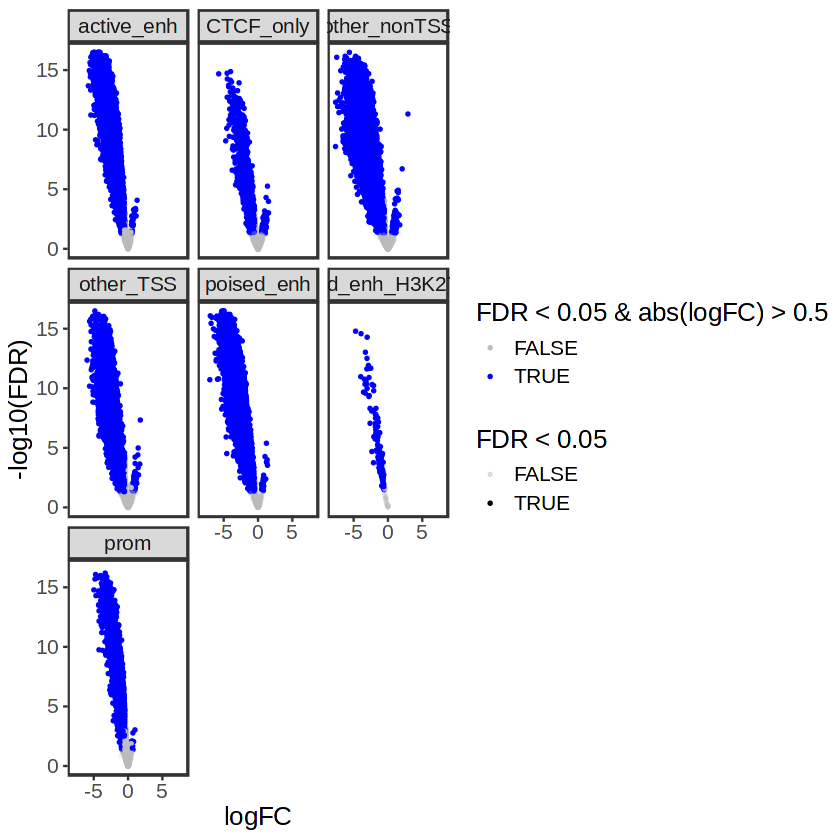

In [12]:
topTags(diff, n=Inf, sort.by="none")$table %>% ggplot(aes(x=logFC,y=-log10(FDR))) + 
    geom_point(size=.5,aes(alpha=FDR<.05,color=FDR < .05 & abs(logFC) > .5) ) + 
    scale_color_manual(values=c("grey", "blue")) + facet_wrap(~consensus_annot$type) + 
    xlim(-8,8)


In [13]:
consensus_annot$type[grep("enh",consensus_annot$type),]

ERROR: Error in consensus_annot$type[grep("enh", consensus_annot$type), ]: incorrect number of dimensions


In [ ]:
topTags(diff, n=Inf, sort.by="none")$table %>% mutate(CTCF=consensus_annot$CTCF) %>% filter(grepl("enh",consensus_annot$type)) %>% ggplot(aes(x=consensus_annot$type[grep("enh",consensus_annot$type)],y=logFC)) +  
    theme(axis.text.x=element_text(angle=45,hjust=1)) + geom_violin(scale="width", linewidth=1) + 
    geom_boxplot(width=.2, outlier.shape=NA) + geom_hline(yintercept=0) + facet_wrap(~CTCF)

In [ ]:
#using default library size normalization

dge3 <- DGEList(counts=countmat[,5:12], group=c("dmso", "dmso", "dmso","dmso","brm", "brm","brm","brm"))
dge3 <- calcNormFactors(dge3)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge$samples)
dge3 <- estimateDisp(dge3, design)

#run DAR analysis
dge3_fit <- glmQLFit(dge3)
diff3 <- glmQLFTest(dge3_fit, contrast=c(1,-1))

In [ ]:
topTags(diff3, n=Inf)$table %>% ggplot(aes(x=logFC,y=-log10(FDR))) + 
    geom_point(size=.01,aes(alpha=FDR<.05,color=FDR < .05 & abs(logFC) > .5) ) + 
    scale_color_manual(values=c("grey", "blue")) + facet_wrap(~consensus_annot$type) + 
    xlim(-8,8)

In [ ]:
dge2 <- DGEList(counts=countmat_control[,5:12], group=c("dmso", "dmso", "dmso","dmso","brm", "brm","brm","brm"))
dge2 <- calcNormFactors(dge2)
#specify design for analysis (here just comparing treatment to control)
design <- model.matrix(~0+group, data=dge2$samples)
dge2 <- estimateDisp(dge2, design)

#this is the key step, where I am calculating normalization factors using the summed counts at invariant promoters as my library sizes
dge$samples$norm.factors <- 1/calcNormFactors(as.matrix(dge2), lib.size=sizes)
#run DAR analysis
dge_fit2 <- glmQLFit(dge2)
diff2 <- glmQLFTest(dge_fit2, contrast=c(1,-1))

In [ ]:
topTags(diff2, n=Inf)$table %>% ggplot(aes(x=logFC,y=-log10(FDR))) + geom_point(shape=21,aes(fill=FDR < .05 & abs(logFC) > 1) ) + scale_fill_manual(values=c("grey", "blue")) + xlim(-8,8) + ylim(0,15) + geom_vline(xintercept=c(-1,1)) + geom_hline(yintercept=-log10(.05))
topTags(diff2, n=Inf)$table %>% group_by(sig=FDR < .05, down=logFC < -1, up=logFC>1) %>% summarize(n=n(), lfc=mean(logFC)) %>% ungroup() %>% summarize(n,sig,up,down,pct=100*n/sum(n))

In [ ]:
sizes